# 4. Позиция «Меркур Авто» и выводы для менеджмента

Сравниваем `Mercur Auto` (включая исходный вариант `Mercur Autos`) с внутренним рынком за январь–сентябрь 2019 года. Базовое сравнение — весь рынок; дополнительное — остальные компании и сопоставимые бренды. Доли по брендам/регионам/сегментам используют **объём соответствующей группы рынка** в знаменателе. Структура продаж компании использует общий объём самой компании.

Нет данных о прибыли, затратах или целевых планах: высокий средний чек не доказывает большую прибыльность или эффективность работы персонала.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

# Тетради можно открывать из папки проекта или из coursework.
ROOT = Path.cwd() if Path('clean_data.py').exists() else Path.cwd() / 'coursework'
sys.path.insert(0, str(ROOT))
import os
os.chdir(ROOT)
from clean_data import load_raw, normalize, aggregate_clean, read_clean, run, validate, CATEGORIES, DROP, COMPANIES, MONTHS
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

import matplotlib.pyplot as plt
from analysis_utils import setup, metrics, breakdown, compare, expanded_values, save_figure, bar, BLUE, GOLD
setup()
df = read_clean('data/autokz2019_clean.csv')
market = df.loc[~df.is_export].copy()
mercur = market.loc[market.company.eq('Mercur Auto')].copy()
positive = market.loc[market.quantity.gt(0)].copy()
Path('tables').mkdir(exist_ok=True)

rest = market.loc[~market.company.eq('Mercur Auto')]
kpis = pd.DataFrame({'Рынок': metrics(market), 'Меркур Авто': metrics(mercur), 'Остальные компании': metrics(rest)}).T
display(kpis)
unit_share = 100 * mercur.quantity.sum() / market.quantity.sum()
value_share = 100 * mercur.total_sales_usd.sum() / market.total_sales_usd.sum()
print(f'Доля в автомобилях: {unit_share:.3f}%; доля в USD: {value_share:.3f}%.')
print(f'Средняя стоимость выше рынка на {(metrics(mercur).avg_vehicle_usd/metrics(market).avg_vehicle_usd-1)*100:.1f}%.')
kpis.to_csv('tables/mercur_kpi.csv', encoding='utf-8-sig')


,net_units,gross_units,returned_units,net_sales_usd,gross_sales_usd,avg_vehicle_usd
Рынок,"34,725.00","34,726.00",1.00,"801,697,865.97","801,733,454.22","23,087.41"
Меркур Авто,394.00,394.00,0.00,"15,121,529.04","15,121,529.04","38,379.52"
Остальные компании,"34,331.00","34,332.00",1.00,"786,576,336.93","786,611,925.18","22,911.92"


Доля в автомобилях: 1.135%; доля в USD: 1.886%.
Средняя стоимость выше рынка на 66.2%.


## Бренды и модели
Доля 100% означает отсутствие других продавцов бренда в предоставленном датасете; это не доказательство монополии на реальном рынке.

,market_units,market_sales_usd,market_mix_pct,mercur_units,mercur_sales_usd,mercur_mix_pct,market_share_pct,mix_gap_pp
brand,,,,,,,,
Volkswagen,1048,"21,654,010.18",3.02,294,"6,299,195.92",74.62,28.05,71.60
Porsche,52,"5,113,512.70",0.15,52,"5,113,512.70",13.20,100.00,13.05
Audi,48,"3,708,820.43",0.14,48,"3,708,820.43",12.18,100.00,12.04


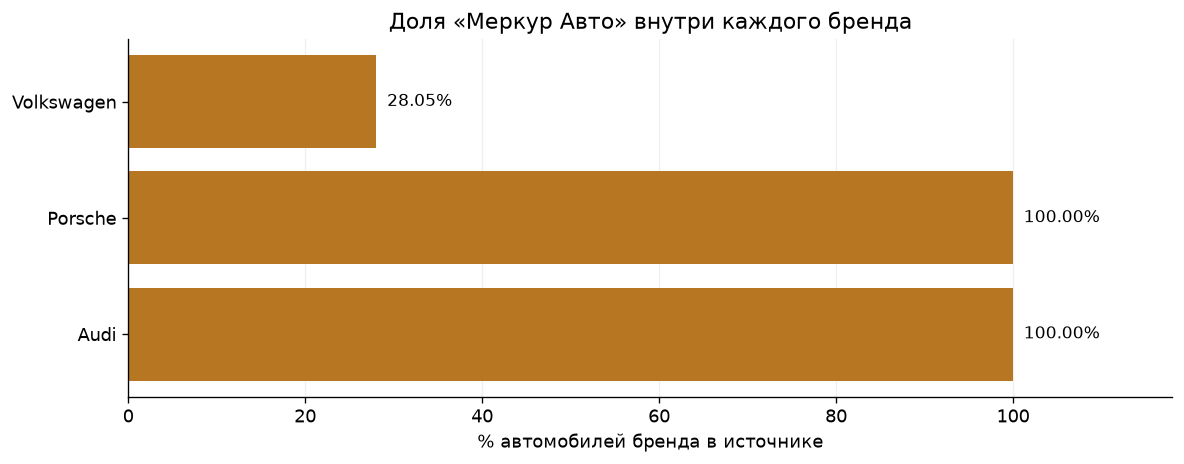

,units,sales_usd,share_pct
brand_model,,,
Volkswagen Polo,202,"2,993,377.30",51.27
Volkswagen Tiguan,67,"2,184,873.71",17.01
Porsche Cayenne,28,"2,856,255.46",7.11
Audi Q8,17,"1,521,388.33",4.31
Porsche Macan,15,"1,015,619.57",3.81
Porsche Panamera,8,"1,079,061.59",2.03
Audi Q5,8,"433,237.39",2.03
Volkswagen Transporter Kasten,7,"214,890.34",1.78
Audi A6,7,"528,752.51",1.78


In [2]:
brand_compare = compare(market, mercur, 'brand')
active_brands = brand_compare.loc[brand_compare.mercur_units.gt(0)]
display(active_brands)
brand_compare.to_csv('tables/mercur_brands.csv', encoding='utf-8-sig')
bar(active_brands.market_share_pct, 'Доля «Меркур Авто» внутри каждого бренда', '% автомобилей бренда в источнике', '13_mercur_brand_share', GOLD)
mercur_models = breakdown(mercur.assign(brand_model=mercur.brand + ' ' + mercur.model), 'brand_model')
display(mercur_models.head(10))
mercur_models.to_csv('tables/mercur_models.csv', encoding='utf-8-sig')

**Интерпретация.** Volkswagen даёт 74.62% объёма «Меркур Авто». При этом Audi и Porsche вместе дают около 58.34% его продаж в USD. Таким образом, массовый объём и денежный вклад распределены между брендами по-разному; нужен раздельный контроль наличия и продаж.

## География и сегменты
Сопоставляем долю компании на локальном рынке и концентрацию её собственных продаж. Нулевое присутствие не означает готовую возможность открытия точки: нужны спрос, затраты и конкурентные условия.

,market_units,market_sales_usd,market_mix_pct,mercur_units,mercur_sales_usd,mercur_mix_pct,market_share_pct,mix_gap_pp
region,,,,,,,,
Алматы,7682,"240,248,212.74",22.12,251,"11,600,584.29",63.71,3.27,41.58
Нур-Султан,5682,"154,143,367.05",16.36,51,"1,502,141.15",12.94,0.90,-3.42
Атырау,2503,"47,873,558.78",7.21,43,"790,024.51",10.91,1.72,3.71
Караганда,2355,"45,234,245.68",6.78,21,"399,332.52",5.33,0.89,-1.45
Костанай,2212,"45,524,698.81",6.37,14,"538,794.64",3.55,0.63,-2.82
Уральск,1743,"33,678,767.49",5.02,14,"290,651.93",3.55,0.80,-1.47
Шымкент,2318,"46,509,184.69",6.68,0,0.00,0.00,0.00,-6.68
Усть-Каменогорск,1865,"35,078,917.15",5.37,0,0.00,0.00,0.00,-5.37
Актобе,1422,"31,748,209.64",4.10,0,0.00,0.00,0.00,-4.10


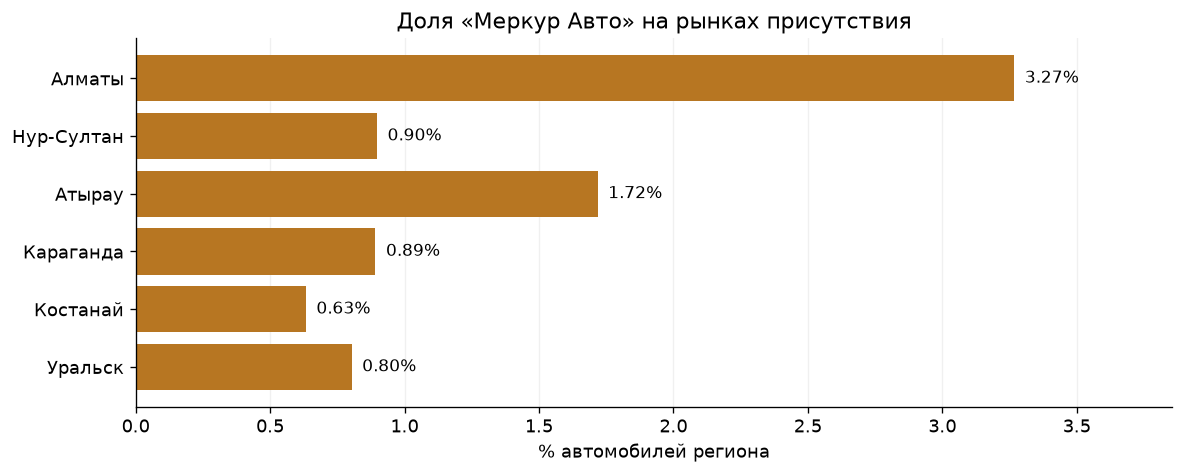

,market_units,market_sales_usd,market_mix_pct,mercur_units,mercur_sales_usd,mercur_mix_pct,market_share_pct,mix_gap_pp
segment_2013,,,,,,,,
Легковые автомобили,15008,"237,043,242.32",43.22,234,"5,809,570.89",59.39,1.56,16.17
Внедорожники,14047,"420,733,988.61",40.45,145,"8,703,315.10",36.80,1.03,-3.65
Коммерческие автомобили,3487,"110,247,450.64",10.04,8,"251,411.12",2.03,0.23,-8.01
Минивэны,1798,"22,213,833.60",5.18,5,"284,190.40",1.27,0.28,-3.91
Пикапы,385,"11,459,350.79",1.11,2,"73,041.55",0.51,0.52,-0.60


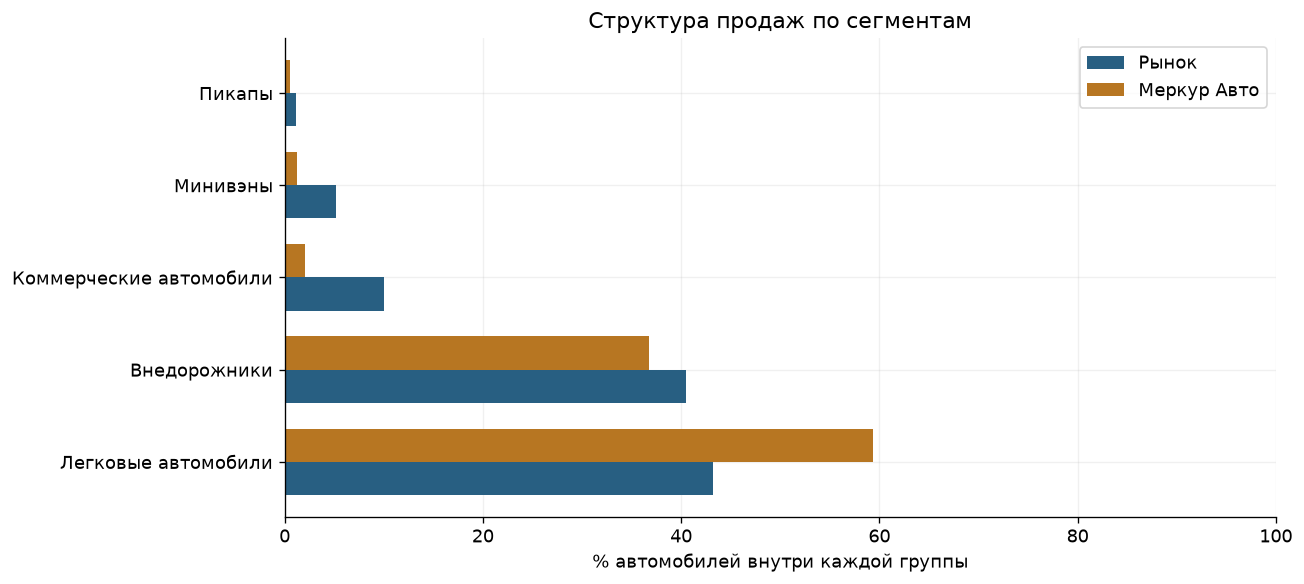

In [3]:
region_compare = compare(market, mercur, 'region')
segment_compare = compare(market, mercur, 'segment_2013')
class_compare = compare(market, mercur, 'class_2013')
for name, table in [('mercur_regions', region_compare), ('mercur_segments', segment_compare), ('mercur_classes', class_compare)]:
    table.to_csv(f'tables/{name}.csv', encoding='utf-8-sig')
display(region_compare)
bar(region_compare.loc[region_compare.mercur_units.gt(0), 'market_share_pct'],
    'Доля «Меркур Авто» на рынках присутствия', '% автомобилей региона', '14_mercur_region_share', GOLD)
display(segment_compare)
fig, ax = plt.subplots(figsize=(11, 5))
positions = np.arange(len(segment_compare))
ax.barh(positions-.18, segment_compare.market_mix_pct, height=.36, color=BLUE, label='Рынок')
ax.barh(positions+.18, segment_compare.mercur_mix_pct, height=.36, color=GOLD, label='Меркур Авто')
ax.set_yticks(positions, segment_compare.index)
ax.set(title='Структура продаж по сегментам', xlabel='% автомобилей внутри каждой группы', xlim=(0, 100))
ax.legend()
save_figure('15_mercur_segment_mix')

**Интерпретация.** Легковые автомобили составляют 59.39% продаж автоцентра против 43.22% рынка; внедорожники — 36.80% против 40.45%. Это специализация портфеля, а не автоматически слабая работа в остальных сегментах. Максимальная локальная доля среди городов присутствия — в Алматы (3.27%).

## Сравнение среднего чека с учётом состава
Показываем цены по брендам и расчёт ожидаемой цены при структуре брендов «Меркур Авто» и среднерыночных ценах этих брендов. Это описательная стандартизация: модели и комплектации всё ещё могут различаться.

In [4]:
def price_by_brand(z):
    p = z.loc[z.quantity.gt(0)]
    out = p.groupby('brand').agg(units=('quantity', 'sum'), revenue=('total_sales_usd', 'sum'))
    out['avg_usd'] = out.revenue/out.units
    return out
market_price = price_by_brand(market)
mercur_price = price_by_brand(mercur)
brand_prices = mercur_price[['units','avg_usd']].join(market_price[['avg_usd']].rename(columns={'avg_usd':'market_avg_usd'}))
rest_price = price_by_brand(rest)
brand_prices = brand_prices.join(rest_price[['avg_usd']].rename(columns={'avg_usd':'others_avg_usd'}))
display(brand_prices)
brand_prices.to_csv('tables/mercur_brand_prices.csv', encoding='utf-8-sig')
standardized = np.average(brand_prices.market_avg_usd, weights=brand_prices.units)
print(f'Средняя рыночная цена при структуре брендов Меркур: {standardized:,.0f} USD.')
print(f'Фактическая цена Меркур: {metrics(mercur).avg_vehicle_usd:,.0f} USD.')
print('Для Audi/Porsche независимого сравнения с другими продавцами в источнике нет.')
fuel_compare = compare(market, mercur, 'fuel_type')
gear_compare = compare(market, mercur, 'transmission')
display(fuel_compare)
display(gear_compare)

,units,avg_usd,market_avg_usd,others_avg_usd
brand,,,,
Audi,48,"77,267.09","77,267.09",<NA>
Porsche,52,"98,336.78","98,336.78",<NA>
Volkswagen,294,"21,425.84","20,662.22","20,364.48"


Средняя рыночная цена при структуре брендов Меркур: 37,810 USD.
Фактическая цена Меркур: 38,380 USD.
Для Audi/Porsche независимого сравнения с другими продавцами в источнике нет.


,market_units,market_sales_usd,market_mix_pct,mercur_units,mercur_sales_usd,mercur_mix_pct,market_share_pct,mix_gap_pp
fuel_type,,,,,,,,
F,30818,"678,853,062.86",88.75,389,"14,567,970.94",98.73,1.26,9.98
HYB,14,"1,096,389.12",0.04,4,"481,450.10",1.02,28.57,0.97
D,903,"51,186,930.59",2.60,1,"72,108.00",0.25,0.11,-2.35
Неизвестно,2985,"69,791,614.29",8.60,0,0.00,0.00,0.00,-8.60
E,5,"769,869.11",0.01,0,0.00,0.00,0.00,-0.01


,market_units,market_sales_usd,market_mix_pct,mercur_units,mercur_sales_usd,mercur_mix_pct,market_share_pct,mix_gap_pp
transmission,,,,,,,,
Автомат,17864,"531,803,278.91",51.44,341,"14,384,408.73",86.55,1.91,35.10
Механика,13904,"195,934,187.03",40.04,52,"723,208.99",13.20,0.37,-26.84
Неизвестно,2957,"73,960,400.03",8.52,1,"13,911.32",0.25,0.03,-8.26


## Что произошло с июня
Сравниваем одинаковые месяцы, отдельно проверяем бренды. Снижение наблюдаемого объёма — факт источника; причины изменения без дополнительных данных не установлены.

,market_units,mercur_units,share_pct
sale_date,,,
2019-01-31,2953,58,1.96
2019-02-28,3193,93,2.91
2019-03-31,3437,62,1.80
2019-04-30,4282,68,1.59
2019-05-31,4257,66,1.55
2019-06-30,4177,8,0.19
2019-07-31,4432,16,0.36
2019-08-31,4250,13,0.31
2019-09-30,3744,10,0.27


brand,Audi,Porsche,Volkswagen
sale_date,,,
2019-01-31,2,1,55
2019-02-28,2,5,86
2019-03-31,9,7,46
2019-04-30,4,8,56
2019-05-31,7,8,51
2019-06-30,3,5,0
2019-07-31,9,7,0
2019-08-31,6,7,0
2019-09-30,6,4,0


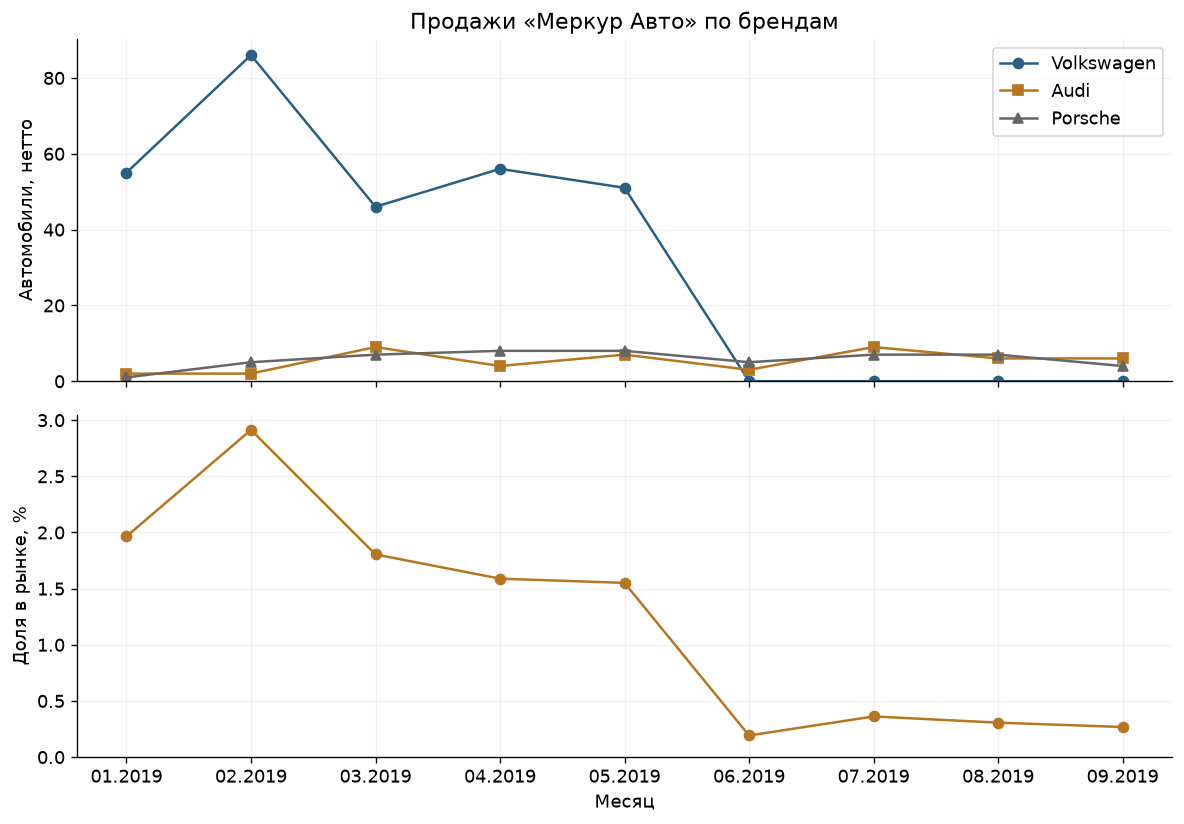

company,Mercur Auto,Volkswagen Group Rus,Автодом Motors KST,Автомир-Центр,"ТОО ""Eurasia Motor Zhaik"""
sale_date,,,,,
2019-01-31,55,0,17,6,8
2019-02-28,86,0,14,0,0
2019-03-31,46,0,0,0,0
2019-04-30,56,6,19,14,7
2019-05-31,51,53,0,14,0
2019-06-30,0,167,0,0,0
2019-07-31,0,93,0,0,0
2019-08-31,0,169,0,0,0
2019-09-30,0,167,0,0,0


In [5]:
monthly = market.groupby('sale_date').quantity.sum().to_frame('market_units')
monthly['mercur_units'] = mercur.groupby('sale_date').quantity.sum()
monthly['share_pct'] = 100*monthly.mercur_units/monthly.market_units
brand_monthly = mercur.pivot_table(index='sale_date', columns='brand', values='quantity', aggfunc='sum', fill_value=0)
display(monthly)
display(brand_monthly)
monthly.to_csv('tables/mercur_monthly.csv')
brand_monthly.to_csv('tables/mercur_monthly_brands.csv')
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
labels = monthly.index.strftime('%m.%Y')
for brand, color, marker in [('Volkswagen', BLUE, 'o'), ('Audi', GOLD, 's'), ('Porsche', '#666666', '^')]:
    axes[0].plot(labels, brand_monthly[brand], color=color, marker=marker, label=brand)
axes[0].set(title='Продажи «Меркур Авто» по брендам', ylabel='Автомобили, нетто', ylim=(0, None))
axes[0].legend()
axes[1].plot(labels, monthly.share_pct, color=GOLD, marker='o')
axes[1].set(ylabel='Доля в рынке, %', xlabel='Месяц', ylim=(0, None))
save_figure('16_mercur_monthly')
vw = market.loc[market.brand.eq('Volkswagen')].pivot_table(index='sale_date', columns='company', values='quantity', aggfunc='sum', fill_value=0)
display(vw)
vw.to_csv('tables/volkswagen_companies_monthly.csv', encoding='utf-8-sig')

С июня у «Меркур Авто» нет ни одной строки Volkswagen; это верно и до удаления дубликатов. Одновременно Volkswagen продолжается под именем Volkswagen Group Rus. **Гипотеза:** изменилась атрибуция/охват поставщика данных или канал продаж. Объединять компании без доказательств нельзя. Поэтому резкое падение нельзя уверенно назвать ухудшением эффективности автоцентра.

In [6]:
raw = load_raw('data/autokz2019_raw.csv')
raw_company = raw['Компания'].str.strip().replace(COMPANIES)
after_may = raw['Месяц'].map(MONTHS).ge(6)
assert not (raw_company.eq('Mercur Auto') & raw['Бренд'].eq('Volkswagen') & after_may).any()
first = mercur.loc[mercur.sale_date.dt.month.le(5), 'quantity'].sum()/5
last = mercur.loc[mercur.sale_date.dt.month.ge(6), 'quantity'].sum()/4
premium_first = mercur.loc[mercur.sale_date.dt.month.le(5) & mercur.brand.ne('Volkswagen'), 'quantity'].sum()/5
premium_last = mercur.loc[mercur.sale_date.dt.month.ge(6) & mercur.brand.ne('Volkswagen'), 'quantity'].sum()/4
print(f'Среднемесячно январь–май: {first:.1f}; июнь–сентябрь: {last:.2f}; изменение: {(last/first-1)*100:.1f}%.')
print(f'Audi+Porsche: {premium_first:.1f} против {premium_last:.2f} автомобиля в месяц.')
display(pd.read_csv('tables/dedup_sensitivity.csv'))

Среднемесячно январь–май: 69.4; июнь–сентябрь: 11.75; изменение: -83.1%.
Audi+Porsche: 10.6 против 11.75 автомобиля в месяц.


,scenario,market_units,mercur_units,mercur_share_pct
0,Без удаления повторов,"51,955.00",650.00,1.25
1,С удалением полных повторов,"34,725.00",394.00,1.13


## Сильные стороны, ограничения и действия

**Наблюдаемые сильные стороны:** компания представлена тремя брендами, занимает 28.05% продаж Volkswagen в источнике и все наблюдаемые продажи Audi/Porsche; денежная доля выше доли в автомобилях. Средняя стоимость автомобиля выше рынка, что связано в том числе с портфелем брендов. Это характеристика позиционирования, не доказательство высокой маржи.

**Уязвимости:** концентрация на Volkswagen (294 из 394 автомобилей), на Алматы (251 из 394), небольшой общий объём и разрыв наблюдения Volkswagen после мая. Нельзя переносить долю первых месяцев на весь год или оценивать результат по единому среднему без разбивки по брендам.

**Рекомендуемые действия:**
1. Сверить продажи Volkswagen за июнь–сентябрь с выгрузкой дилерской системы и правилами атрибуции компаний. До проверки не делать кадровых или бюджетных выводов из падения.
2. Для Volkswagen сравнить наличие, цены, лиды и конверсию по моделям с сопоставимыми продавцами; проверить спрос на наиболее продаваемые модели внутри доступного бренда. Большой рынок Lada сам по себе не означает возможность продавать этот бренд.
3. В Алматы проверить удержание и работу с существующими клиентами; для Нур-Султана проверить спрос и экономику расширения. Присутствие в городе и большой общий рынок не доказывают окупаемости новой точки.
4. Для Audi/Porsche вести отдельные KPI: объём, маржа, оборачиваемость запасов, конверсия. Внешнее конкурентное сравнение потребует дополнительного источника.

**Сверка с заданием:** доли по брендам, регионам и сегментам; KPI и средний чек; структура и динамика продаж; сравнение с рынком; сильные и слабые стороны и рекомендации выполнены. Выводы ограничены качеством и охватом исходных данных.